# Create a Bathymetry Surface Using Individual Scenes

*Section 10 — Case study: ICESat-2 bathymetry, notebook 4 of 5.* Previous: `03_landsat_composite_bathymetry`. Next: `05_cshelph_bathymetry` (optional).

**You will learn:**
- how to loop through a set of scenes, sampling each and training and applying a regression model per scene;
- how to combine valid-data and water masks with `band_maths`;
- how to summarise the per-scene results into min, max, mean, median, standard deviation and standard error surfaces (`calc_multi_img_band_stats`);
- how to compare the accuracy of the summaries with `rsgispy.regression.regmetrics` (metrics, predicted v observed, residual and QQ plots for several predictions at once);
- how to draw several maps with colour bars side by side (`rsgispy.mapping.layout.create_map_panels`).

**Before you start:** `03_landsat_composite_bathymetry` of this section (this notebook repeats its steps for each scene and compares the results with it). Regression is introduced in section 5 (`05_regression`).

**Data:** the 11 Landsat scenes in `../data/is2_bathy/ls_imgs/`, `../data/is2_bathy/is2_bermuda_depth.gpkg`, `../data/is2_bathy/bermuda_land_area.geojson` and `../data/is2_bathy/bermuda_valid_water_mask.geojson`.

**Run time:** about 1 minute.

An alternative approach to creating an image composite is to use each of the individual scenes, predict a bathymetric surface from each and then combine those results to create a single bathymetric surface.

I prefer this method for the following reasons:

 1. Creating a composite of satellite imagery will often produce image artifacts which are then passed through into any output products which are generated from that composite.
 2. By having multiple estimates of the depth a per-pixel standard error surface can be calculated which provides an uncertainty surface which is useful for users of your bathymetric product.

# 1. Imports

In [1]:
import glob
import os

import geopandas
import matplotlib.pyplot as plt
import pandas
import rsgispy
import rsgispy.imagecalc.maths
import rsgispy.imagecalc.stats
import rsgispy.imageutils.colourtable
import rsgispy.imageutils.masking
import rsgispy.imageutils.metadata
import rsgispy.imageutils.rasterise
import rsgispy.imageutils.stats
import rsgispy.mapping.layout as map_layout
import rsgispy.regression.regmetrics
import rsgispy.regression.regsklearn
import rsgispy.tools.files
import rsgispy.vector.io
import rsgispy.vector.selection
import rsgispy.zonalstats.point
from rsgispy.imageutils.masking import ImageBandInfo

# Import Random Forests RandomForestRegressor
from sklearn.ensemble import RandomForestRegressor

# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline

# 2. Define Input Datasets

In [2]:
# Get the input landsat image file paths.
landsat_imgs = sorted(glob.glob("../data/is2_bathy/ls_imgs/*.tif"))

# The original ICESat-2 data.
is2_vec_file = "../data/is2_bathy/is2_bermuda_depth.gpkg"

# The land area vector layer for defining the valid area
land_area_vec_file = "../data/is2_bathy/bermuda_land_area.geojson"
land_area_vec_lyr = "bermuda_land_area"

# The ocean water area vector layer
ocean_area_vec_file = "../data/is2_bathy/bermuda_valid_water_mask.geojson"
ocean_area_vec_lyr = "bermuda_valid_water_mask"

out_dir = "outputs/ls_scns"
os.makedirs(out_dir, exist_ok=True)

# 3. Merge ICESat-2 Paths

The ICESat-2 data has been provided to you as a multi-layer vector file. For this analysis we want just a single vector layer so we do not have to repeat processing steps for the different layers. The following command merges the vector layers into a single layer.

In [3]:
is2_all_vec_file = os.path.join(out_dir, "is2_bermuda_depth_sgl_lyr_all.gpkg")
is2_all_vec_lyr = "is2_bermuda_depth_sgl_lyr_all"
# Remove the output if it already exists (e.g., the notebook is re-run).
if os.path.exists(is2_all_vec_file):
    rsgispy.vector.io.delete_vec_file(is2_all_vec_file)
rsgispy.vector.io.merge_vec_file_lyrs(
    is2_vec_file, out_vec_file=is2_all_vec_file, out_vec_lyr=is2_all_vec_lyr
)

  0%|          | 0/1 [00:00<?, ?it/s]

# 4. Extract Random Sample of ICESat-2 Returns

This step will extract a random 20 % sample of all the ICESat-2 returns and these will be used to validate the final bathymetry surfaces. Given the large number of returns in the ICESat-2 data, taking a sample to use as a validation dataset is a good idea as while k-fold and bootstrapping can be used to derive statistics on the model accuracy it is ideal to have an independent dataset. The same random seed as the previous notebook is used, so the test points are the same and the results can be compared.

In [4]:
is2_train_vec_file = os.path.join(out_dir, "is2_bermuda_depth_train.gpkg")
is2_train_vec_lyr = "is2_bermuda_depth_train"
is2_test_vec_file = os.path.join(out_dir, "is2_bermuda_depth_test.gpkg")
is2_test_vec_lyr = "is2_bermuda_depth_test"

rsgispy.vector.selection.create_train_test_smpls(
    is2_all_vec_file,
    is2_all_vec_lyr,
    is2_train_vec_file,
    is2_train_vec_lyr,
    is2_test_vec_file,
    is2_test_vec_lyr,
    out_format="GPKG",
    prop_test=0.2,
    rnd_seed=42,
    del_exist_vec=True,
)
print(f"Number of Training Features: {rsgispy.vector.io.get_vec_feat_count(is2_train_vec_file, is2_train_vec_lyr)}")
print(f"Number of Testing Features: {rsgispy.vector.io.get_vec_feat_count(is2_test_vec_file, is2_test_vec_lyr)}")

Number of Training Features: 29621
Number of Testing Features: 7405


# 5. Check the Data Projections.

A common error which can occur when combining datasets from different sources is that they are in different projections.

In this case there are multiple input images so we need to loop through them all and check they each match the ICESat-2 data.

In [5]:
is2_epsg = rsgispy.vector.io.get_epsg_proj_from_vec(
    is2_vec_file, vec_lyr="ic2_depth_bermuda_path1"
)

# Iterate through the input images and check they all have matching projections.
projects_match = True
for ls_img in landsat_imgs:
    ls_img_epsg = rsgispy.imageutils.metadata.get_epsg_proj_from_img(ls_img)

    if is2_epsg != ls_img_epsg:
        projects_match = False

if projects_match:
    print("Datasets have matching projections")
else:
    print("Projections DO NOT match - you probably need to sort something out here...")

Datasets have matching projections


# 6. Define the Valid Area to Apply the Model to

Before applying the model we need to define the area for which the model should be applied. For this analysis that will be over the areas of water so we need to mask the land area. You have been supplied a vector layer of the land area so let's use that to create a mask. `set_thematic_classes` names the class ("Water") and gives it a colour.

In [6]:
land_area_img = os.path.join(out_dir, "bermuda_land_area.tif")
rsgispy.imageutils.rasterise.rasterise_vec_lyr(
    land_area_vec_file,
    land_area_vec_lyr,
    landsat_imgs[0],
    output_img=land_area_img,
    burn_val=1,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_8UINT,
)

water_area_img = os.path.join(out_dir, "bermuda_water_area.tif")
rsgispy.imagecalc.maths.image_math(
    land_area_img,
    water_area_img,
    "b1==1?0:1",
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_8UINT,
)
rsgispy.imageutils.colourtable.set_thematic_classes(
    water_area_img, {1: ("Water", "#1E88E5")}
)

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

# 7. Iterate Through Landsat Images

For each scene the following analysis needs to be undertaken:

 1. Extract the Landsat reflectance values at the ICESat-2 training points. The points are read into memory once (a GeoDataFrame) and the values for each scene are extracted into a copy, which is saved to a new points file for each Landsat image.
 2. Remove invalid ICESat-2 points which do not have Landsat reflectance values.
 3. Train the regression algorithm.
 4. Create a mask of the pixels with valid data in the scene and in the water area.
 5. Apply the regression algorithm.

> **RSGISLib users:** `vectorutils.read_vec_lyr_to_mem` and `write_vec_lyr_to_file` are not needed: the rsgispy vector and zonal statistics functions accept and return GeoDataFrames, which are written with GeoPandas (`to_file`). `drop_rows_by_multi_attributes` replaces the repeated `drop_rows_by_attribute` calls.

In [7]:
ind_vars = ["ls_coastal", "ls_blue", "ls_green"]
depth_var = "Depth"

# Read the training points into memory once.
is2_train_gdf = geopandas.read_file(is2_train_vec_file, layer=is2_train_vec_lyr)

bathy_imgs = list()
vld_msk_imgs = list()

for ls_img in landsat_imgs:
    ls_basename = rsgispy.tools.files.get_file_basename(ls_img)
    print(ls_basename)

    # 1. Extract the coastal, blue and green values at the points
    pts_gdf = rsgispy.zonalstats.point.ext_point_band_values(
        is2_train_gdf.copy(),
        ls_img,
        img_band=[1, 2, 3],
        min_thres=-100,
        max_thres=10000,
        out_no_data_val=-9999,
        out_field=ind_vars,
        use_pbar=False,
    )
    vec_ls_stats_lyr = f"{ls_basename}_is2_pts"
    vec_ls_stats_file = os.path.join(out_dir, f"{vec_ls_stats_lyr}.gpkg")
    pts_gdf.to_file(vec_ls_stats_file, layer=vec_ls_stats_lyr, driver="GPKG")

    # 2. Remove the points without valid values for all three bands
    vld_gdf = rsgispy.vector.selection.drop_rows_by_multi_attributes(
        pts_gdf, None, drop_atts={var: -9999 for var in ind_vars}
    )
    print(f"\t{len(vld_gdf)} of {len(pts_gdf)} points are valid")

    # 3. Train a random forests regression
    skregrs_obj = RandomForestRegressor(n_jobs=-1, random_state=42)
    skregrs_obj.fit(vld_gdf[ind_vars], vld_gdf[depth_var].values)

    # 4. Create a valid data mask for the input image and combine with the water mask.
    vld_msk_img = os.path.join(out_dir, f"{ls_basename}_vld_msk.tif")
    rsgispy.imageutils.masking.gen_valid_mask(
        ls_img, vld_msk_img, gdalformat="GTIFF", no_data_val=-9999, use_pbar=False
    )

    water_area_vld_msk_img = os.path.join(out_dir, f"{ls_basename}_water_vld_msk.tif")
    band_defns = [
        rsgispy.imagecalc.maths.BandDefn("vld", vld_msk_img, 1),
        rsgispy.imagecalc.maths.BandDefn("water", water_area_img, 1),
    ]
    rsgispy.imagecalc.maths.band_maths(
        water_area_vld_msk_img,
        "(vld==1)&&(water==1)?1:0",
        band_defns,
        gdalformat="GTIFF",
        datatype=rsgispy.TYPE_8UINT,
        use_pbar=False,
    )
    rsgispy.imageutils.colourtable.set_thematic_classes(
        water_area_vld_msk_img, {1: ("Valid water", "#1E88E5")}
    )

    # 5. Apply regression to landsat image.
    bathy_depths_img = os.path.join(out_dir, f"{ls_basename}_bathy_rslt.tif")
    rsgispy.regression.regsklearn.apply_sklearn_regressor(
        None,
        skregrs_obj,
        water_area_vld_msk_img,
        1,
        bathy_depths_img,
        img_band_info=[
            ImageBandInfo(ls_img, name="landsat", bands=[1, 2, 3], band_names=ind_vars)
        ],
        target_cols="Depth",
        gdalformat="GTIFF",
        out_no_data_val=0.0,
        calc_stats=True,
        use_pbar=False,
    )
    bathy_imgs.append(bathy_depths_img)
    vld_msk_imgs.append(water_area_vld_msk_img)

lc08_l2sp_006037_20150122_20200910_02_t1_sref_sub_mskd
	29222 of 29621 points are valid


lc08_l2sp_006037_20180623_20200831_02_t1_sref_sub_mskd
	19081 of 29621 points are valid


lc08_l2sp_006038_20170417_20200904_02_t1_sref_sub_mskd
	29456 of 29621 points are valid


lc08_l2sp_006038_20170807_20200903_02_t1_sref_sub_mskd
	26125 of 29621 points are valid


lc08_l2sp_006038_20180522_20200901_02_t1_sref_sub_mskd
	25990 of 29621 points are valid


lc08_l2sp_006038_20190829_20200826_02_t1_sref_sub_mskd
	18388 of 29621 points are valid


lc08_l2sp_006038_20210311_20210317_02_t1_sref_sub_mskd
	25705 of 29621 points are valid


lc08_l2sp_006038_20210615_20210622_02_t1_sref_sub_mskd
	1430 of 29621 points are valid


lc08_l2sp_006038_20210802_20210811_02_t1_sref_sub_mskd
	22065 of 29621 points are valid


lc08_l2sp_006038_20211021_20211103_02_t1_sref_sub_mskd
	18835 of 29621 points are valid


lc09_l2sp_006038_20220101_20220123_02_t1_sref_sub_mskd
	29591 of 29621 points are valid


# 8. Merge Scene Outputs

`calc_multi_img_band_stats` calculates a per-pixel summary statistic across the images, ignoring the no data value (0). It does not set the no data value on its output, so a small helper function does that and calculates the image statistics.

For the count of the number of observations the valid masks are summed (here the 0 values are counted, so `use_no_data=False`).

In [8]:
def calc_summary_img(in_imgs, out_img, sum_stat):
    """Per-pixel summary of the depth images (no data = 0)."""
    rsgispy.imagecalc.stats.calc_multi_img_band_stats(
        in_imgs,
        out_img,
        sum_stat,
        use_no_data=True,
        gdalformat="GTIFF",
        datatype=rsgispy.TYPE_32FLOAT,
        no_data_val=0.0,
        use_pbar=False,
    )
    rsgispy.imageutils.metadata.set_img_no_data_value(out_img, 0.0)
    rsgispy.imageutils.stats.pop_img_stats(out_img, no_data_val=0, calc_pyramids=True)


# The per-pixel summary statistics of the depths from all the scenes.
# 0 is the no data value of the depth images (all valid depths are negative).
bathy_depth_min_img = os.path.join(out_dir, "bermuda_bathy_min.tif")
calc_summary_img(bathy_imgs, bathy_depth_min_img, rsgispy.SUMTYPE_MIN)

bathy_depth_max_img = os.path.join(out_dir, "bermuda_bathy_max.tif")
calc_summary_img(bathy_imgs, bathy_depth_max_img, rsgispy.SUMTYPE_MAX)

bathy_depth_mean_img = os.path.join(out_dir, "bermuda_bathy_mean.tif")
calc_summary_img(bathy_imgs, bathy_depth_mean_img, rsgispy.SUMTYPE_MEAN)

bathy_depth_median_img = os.path.join(out_dir, "bermuda_bathy_median.tif")
calc_summary_img(bathy_imgs, bathy_depth_median_img, rsgispy.SUMTYPE_MEDIAN)

bathy_depth_stdev_img = os.path.join(out_dir, "bermuda_bathy_stdev.tif")
calc_summary_img(bathy_imgs, bathy_depth_stdev_img, rsgispy.SUMTYPE_STDDEV)

# Calculate the count of the number of observations
bathy_depth_count_img = os.path.join(out_dir, "bermuda_bathy_count.tif")
rsgispy.imagecalc.stats.calc_multi_img_band_stats(
    vld_msk_imgs,
    bathy_depth_count_img,
    rsgispy.SUMTYPE_SUM,
    use_no_data=False,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_8UINT,
    use_pbar=False,
)
rsgispy.imageutils.metadata.set_img_no_data_value(bathy_depth_count_img, 0)
rsgispy.imageutils.stats.pop_img_stats(bathy_depth_count_img, no_data_val=0, calc_pyramids=True)

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

... (2 outputs left out)

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

# 9. Calculate the Standard Error

Standard deviation and standard error are both used in all types of statistical studies. In these studies, the standard deviation and the estimated standard error are used to present the characteristics of sample data and explain statistical analysis results.

However, some researchers occasionally confuse the standard deviation and the standard error. Such researchers should remember that the calculations for standard deviation and standard error include different statistical inferences, each of them with its own meaning. Standard deviation is the dispersion of individual data values. In other words, standard deviation indicates how accurately the mean represents sample data. While the meaning of standard error includes statistical inference based on the sampling distribution. Standard error is the standard deviation of the theoretical distribution of the sample means (the sampling distribution).

In [9]:
# Calculate standard error bathymetric depth
bathy_depth_stderr_img = os.path.join(out_dir, "bermuda_bathy_std_err.tif")

band_defns = [
    rsgispy.imagecalc.maths.BandDefn("std", bathy_depth_stdev_img, 1),
    rsgispy.imagecalc.maths.BandDefn("n", bathy_depth_count_img, 1),
]
rsgispy.imagecalc.maths.band_maths(
    bathy_depth_stderr_img,
    "n>0?std/sqrt(n):0",
    band_defns,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_32FLOAT,
    no_data_val=0,
)
rsgispy.imageutils.stats.pop_img_stats(bathy_depth_stderr_img, no_data_val=0, calc_pyramids=True)

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

# 10. Visualise Results

`create_map_panels` draws the six summaries side by side with the same extent, each with its own colour bar.

It is highly recommended that you also open these images in TuiView or QGIS and have a proper look at the data. What artifacts do you see? What are the pixel values? How do they compare?

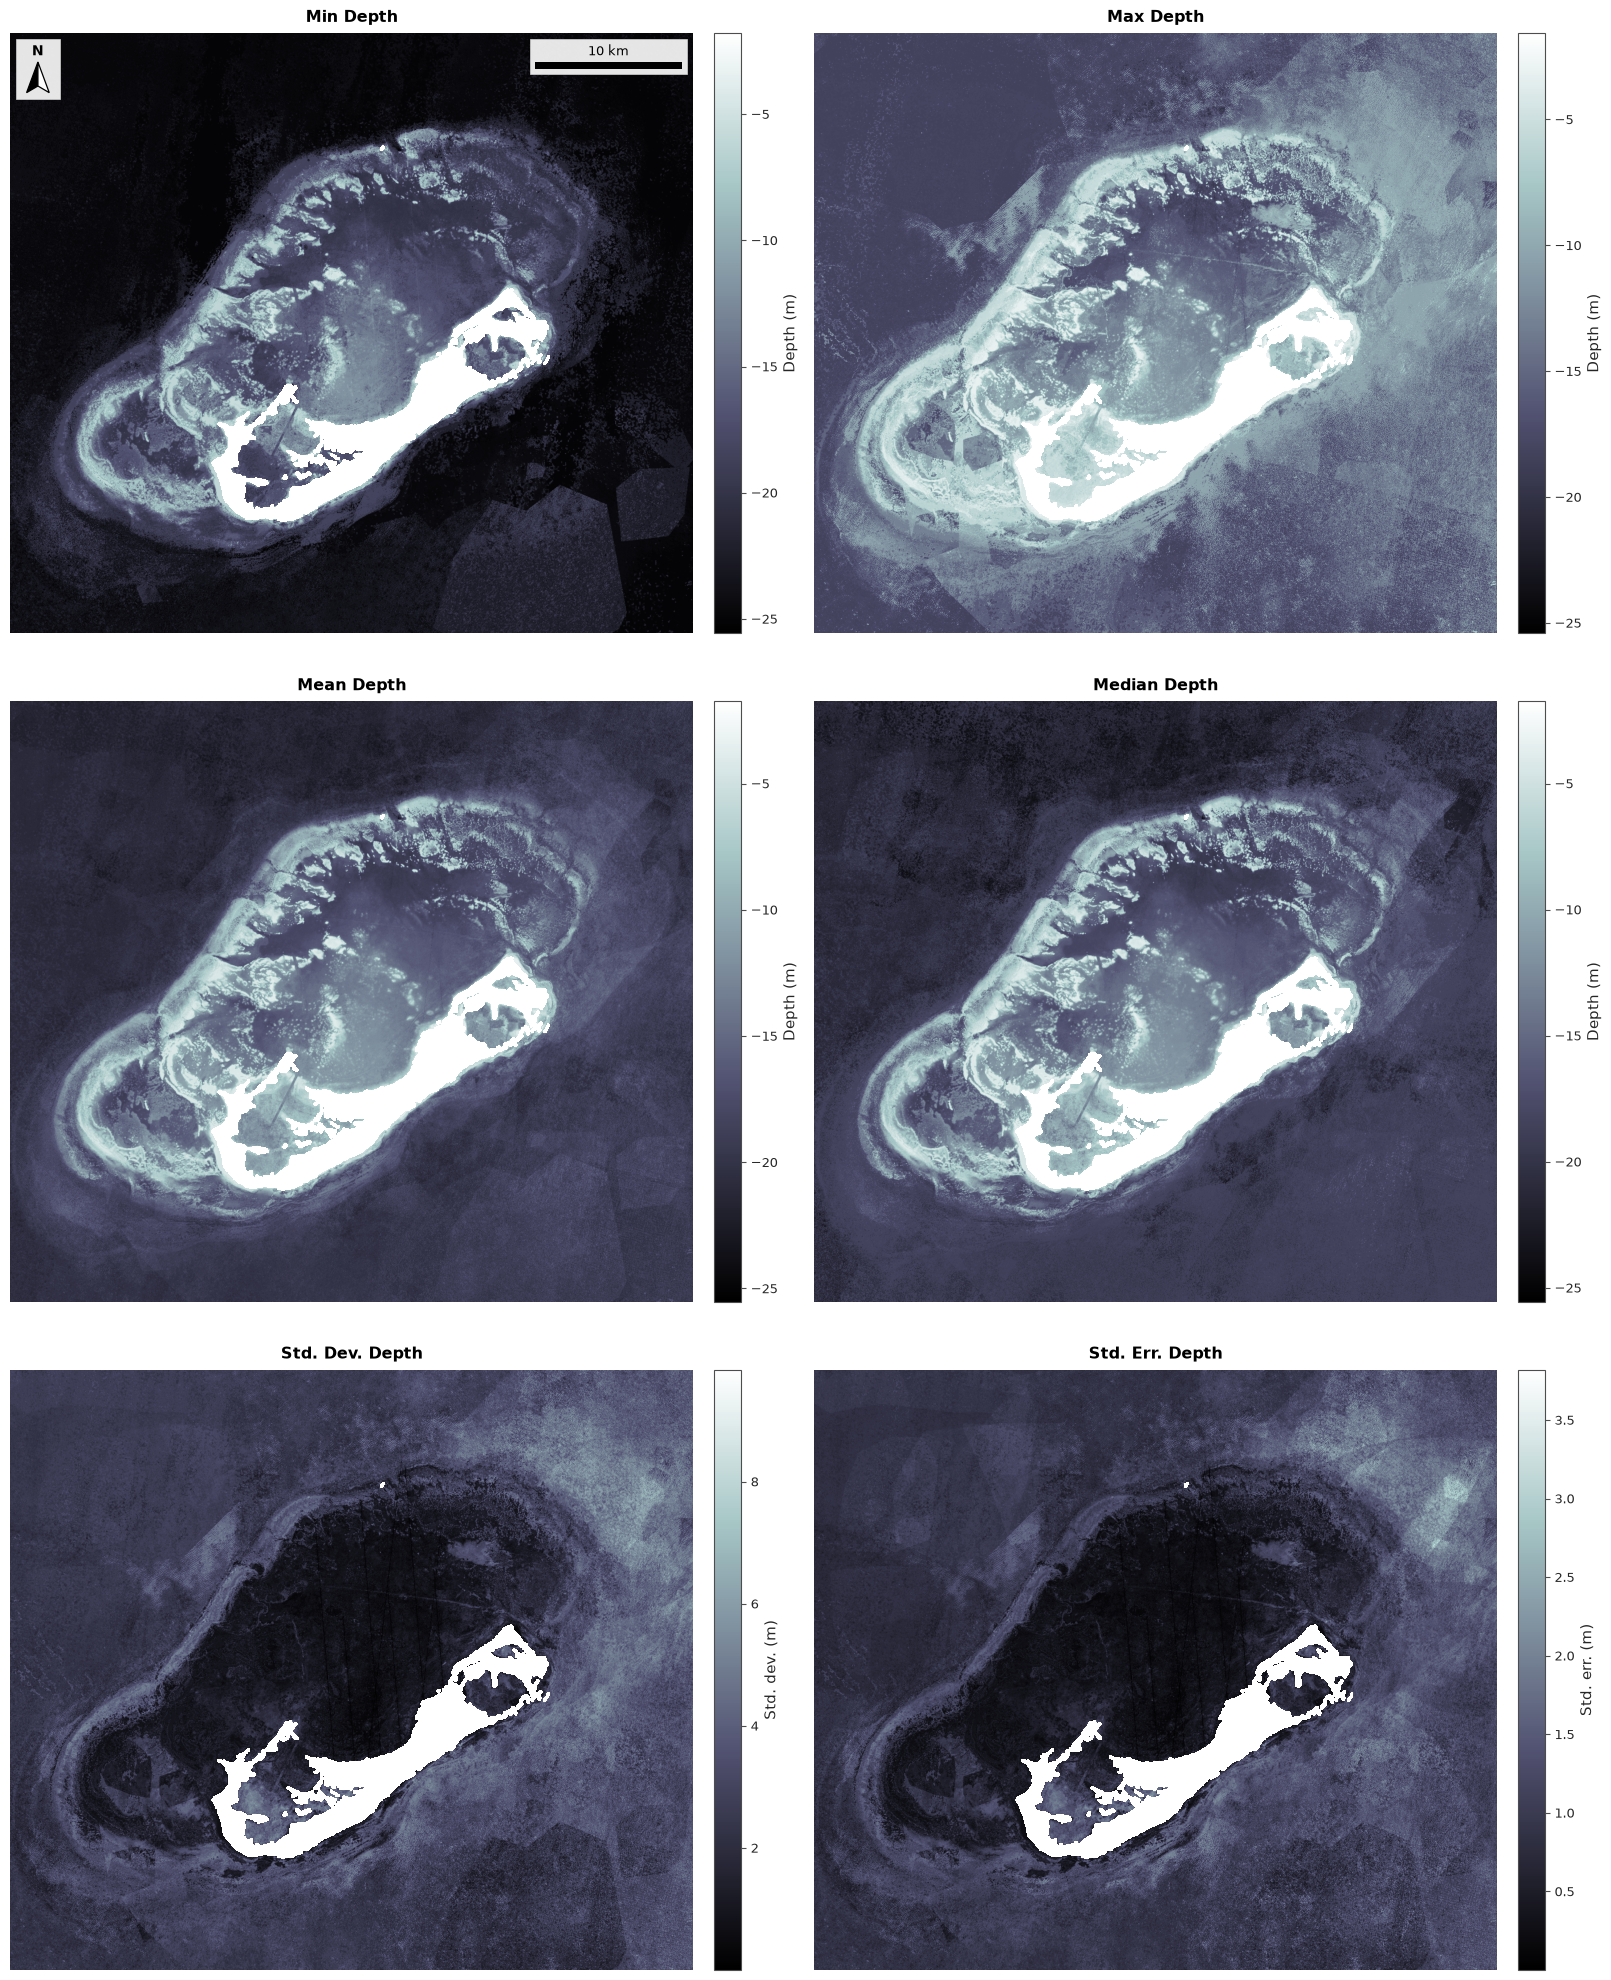

In [10]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "cmap",
            img,
            cmap_name="bone",
            title=title,
            show_colour_bar=True,
            cbar_label=cbar_label,
        )
        for title, img, cbar_label in [
            ("Min Depth", bathy_depth_min_img, "Depth (m)"),
            ("Max Depth", bathy_depth_max_img, "Depth (m)"),
            ("Mean Depth", bathy_depth_mean_img, "Depth (m)"),
            ("Median Depth", bathy_depth_median_img, "Depth (m)"),
            ("Std. Dev. Depth", bathy_depth_stdev_img, "Std. dev. (m)"),
            ("Std. Err. Depth", bathy_depth_stderr_img, "Std. err. (m)"),
        ]
    ],
    ncols=2,
    figsize=(16, 20),
)

## 10.1 So, what can we see in these images?

The first thing to note is that the minimum depth is the deepest value (i.e., furthest away from the water surface) while the maximum is the shallowest (i.e., closest to the water surface).

The min and max values are sensitive to extreme values so the mean and median tend to be the better results. In this case, the result looks pretty similar for the mean and median but if there is more noise (e.g., missed cloud in some of the input images) then you will probably find the median is a better result with fewer artifacts.

The standard deviation and standard error images look pretty similar but you can see that the further from the ICESat-2 paths the values are increasing and you can see that particularly in the areas of deep water the values are significantly higher as there is little or no training data in these areas. You can even see the locations of the ICESat-2 paths which have been used for training as these have produced very similar values for the depth from each scene as those pixels were included in the training.

# 11. Mask to the Valid Area

This could have been done before the analysis and merged with the valid mask which was passed to the `apply_sklearn_regressor` function. However, for illustration purposes it was useful to have the standard deviation and standard error values for the wider region. We will therefore apply the mask to all the images now, with `mask_img`: the pixels where the ocean mask is 1 are set to 0 (no data).

In [11]:
ocean_area_img = os.path.join(out_dir, "bermuda_ocean_area.tif")
rsgispy.imageutils.rasterise.rasterise_vec_lyr(
    ocean_area_vec_file,
    ocean_area_vec_lyr,
    landsat_imgs[0],
    output_img=ocean_area_img,
    burn_val=1,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_8UINT,
)

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

In [12]:
bathy_depth_min_fnl_img = os.path.join(out_dir, "bermuda_bathy_min_fnl.tif")
bathy_depth_max_fnl_img = os.path.join(out_dir, "bermuda_bathy_max_fnl.tif")
bathy_depth_mean_fnl_img = os.path.join(out_dir, "bermuda_bathy_mean_fnl.tif")
bathy_depth_median_fnl_img = os.path.join(out_dir, "bermuda_bathy_median_fnl.tif")
bathy_depth_stdev_fnl_img = os.path.join(out_dir, "bermuda_bathy_stdev_fnl.tif")
bathy_depth_stderr_fnl_img = os.path.join(out_dir, "bermuda_bathy_std_err_fnl.tif")

for in_img, out_img in [
    (bathy_depth_min_img, bathy_depth_min_fnl_img),
    (bathy_depth_max_img, bathy_depth_max_fnl_img),
    (bathy_depth_mean_img, bathy_depth_mean_fnl_img),
    (bathy_depth_median_img, bathy_depth_median_fnl_img),
    (bathy_depth_stdev_img, bathy_depth_stdev_fnl_img),
    (bathy_depth_stderr_img, bathy_depth_stderr_fnl_img),
]:
    # Pixels where the ocean mask is 1 are set to 0 (no data)
    rsgispy.imageutils.masking.mask_img(
        in_img,
        ocean_area_img,
        out_img,
        out_value=0,
        mask_value=1,
        gdalformat="GTIFF",
        datatype=rsgispy.TYPE_32FLOAT,
        no_data_val=0,
        calc_stats=True,
        use_pbar=False,
    )

## 11.1 Visualise the Masked Images

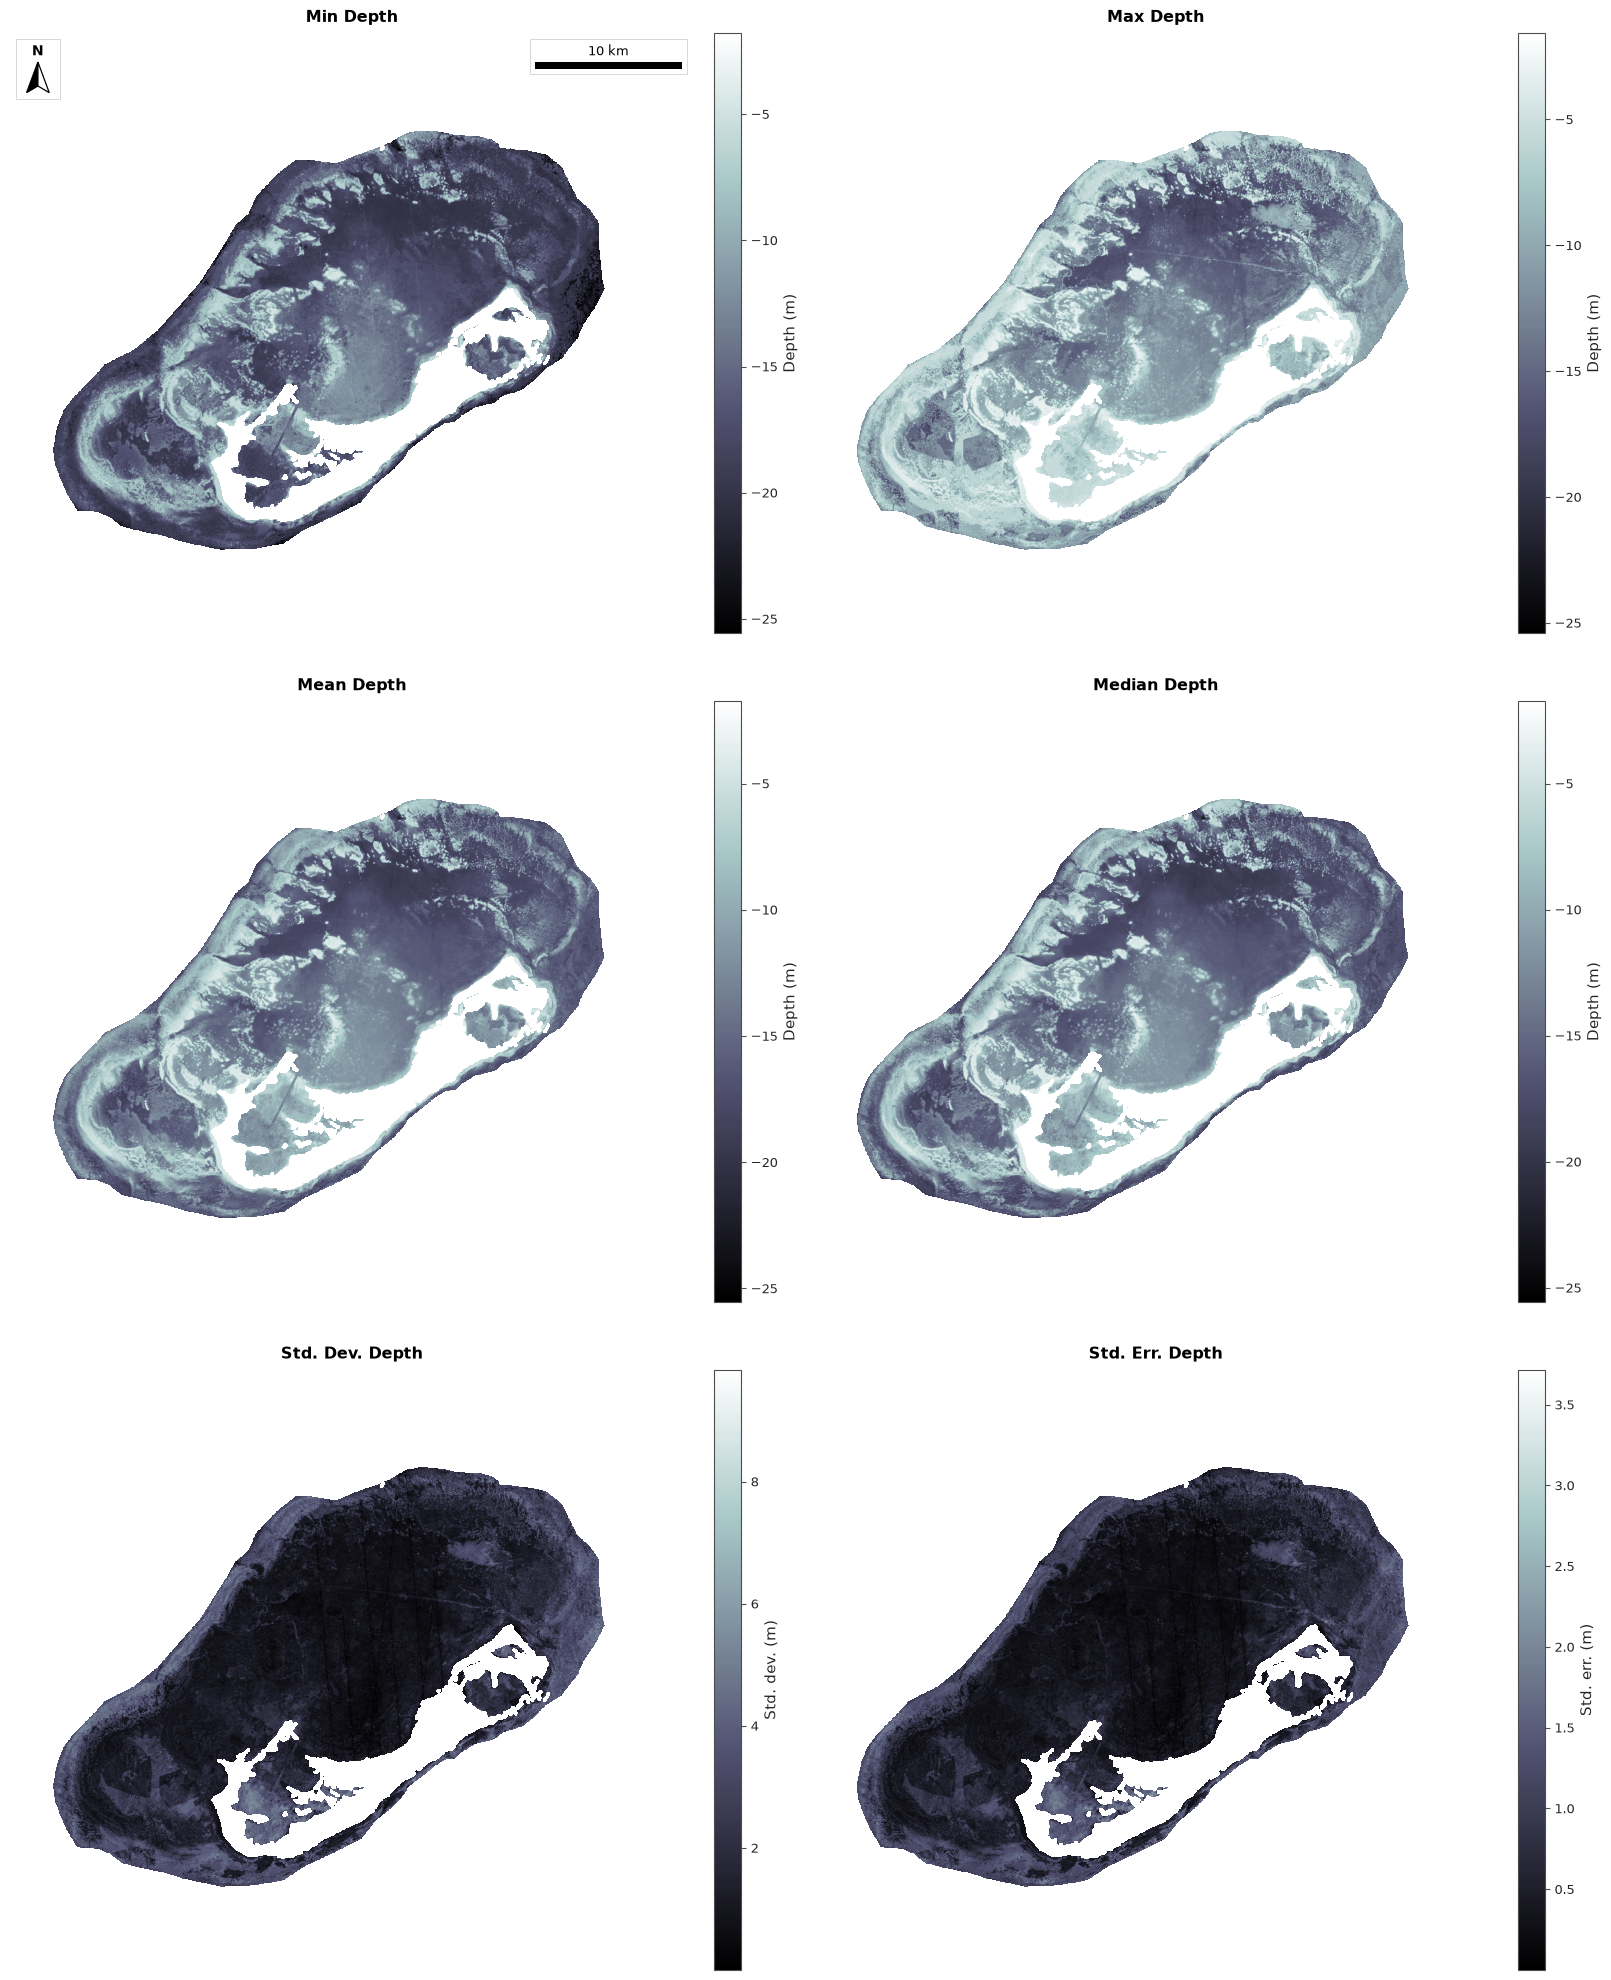

In [13]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "cmap",
            img,
            cmap_name="bone",
            title=title,
            show_colour_bar=True,
            cbar_label=cbar_label,
        )
        for title, img, cbar_label in [
            ("Min Depth", bathy_depth_min_fnl_img, "Depth (m)"),
            ("Max Depth", bathy_depth_max_fnl_img, "Depth (m)"),
            ("Mean Depth", bathy_depth_mean_fnl_img, "Depth (m)"),
            ("Median Depth", bathy_depth_median_fnl_img, "Depth (m)"),
            ("Std. Dev. Depth", bathy_depth_stdev_fnl_img, "Std. dev. (m)"),
            ("Std. Err. Depth", bathy_depth_stderr_fnl_img, "Std. err. (m)"),
        ]
    ],
    ncols=2,
    figsize=(16, 20),
)

# 12. Assess the Quality of the Result

## 12.1 Extract the Predicted Depths at the Test Points

`ext_point_band_values_file` is called once per image, adding a column to the test points file each time.

In [14]:
for col, img in [
    ("min_depth", bathy_depth_min_fnl_img),
    ("max_depth", bathy_depth_max_fnl_img),
    ("mean_depth", bathy_depth_mean_fnl_img),
    ("median_depth", bathy_depth_median_fnl_img),
]:
    rsgispy.zonalstats.point.ext_point_band_values_file(
        is2_test_vec_file,
        is2_test_vec_lyr,
        img,
        img_band=1,
        min_thres=-50,
        max_thres=-0.0001,
        out_no_data_val=9999,
        out_field=col,
        use_pbar=False,
    )

Only the test points with a valid value in all four images are kept, so the four summaries are compared using exactly the same points.

In [15]:
# Open the GPKG file as a geopandas data frame - the gdf variable.
gdf = geopandas.read_file(is2_test_vec_file, layer=is2_test_vec_lyr)

print("All Columns: ", list(gdf.columns))

depth_cols = ["min_depth", "max_depth", "mean_depth", "median_depth"]
vld_gpdf = gdf[(gdf[depth_cols] != 9999).all(axis=1)]
print(f"There were {len(gdf)} rows which reduced to {len(vld_gpdf)}")

All Columns:  ['field_1', 'Longitude', 'Latitude', 'PhotonHeig', 'Depth', 'LandConfid', 'min_depth', 'max_depth', 'mean_depth', 'median_depth', 'geometry']
There were 7405 rows which reduced to 7254


## 12.2 Plot Reference v Predicted

`plot_pred_vs_obs` is called for each of the four summaries, drawing on the axes of a 2 x 2 figure (`axs=ax`). It can also plot several predictions in one call (`ref_cols` and `pred_cols`, one panel each), but it then puts up to three panels on each row.

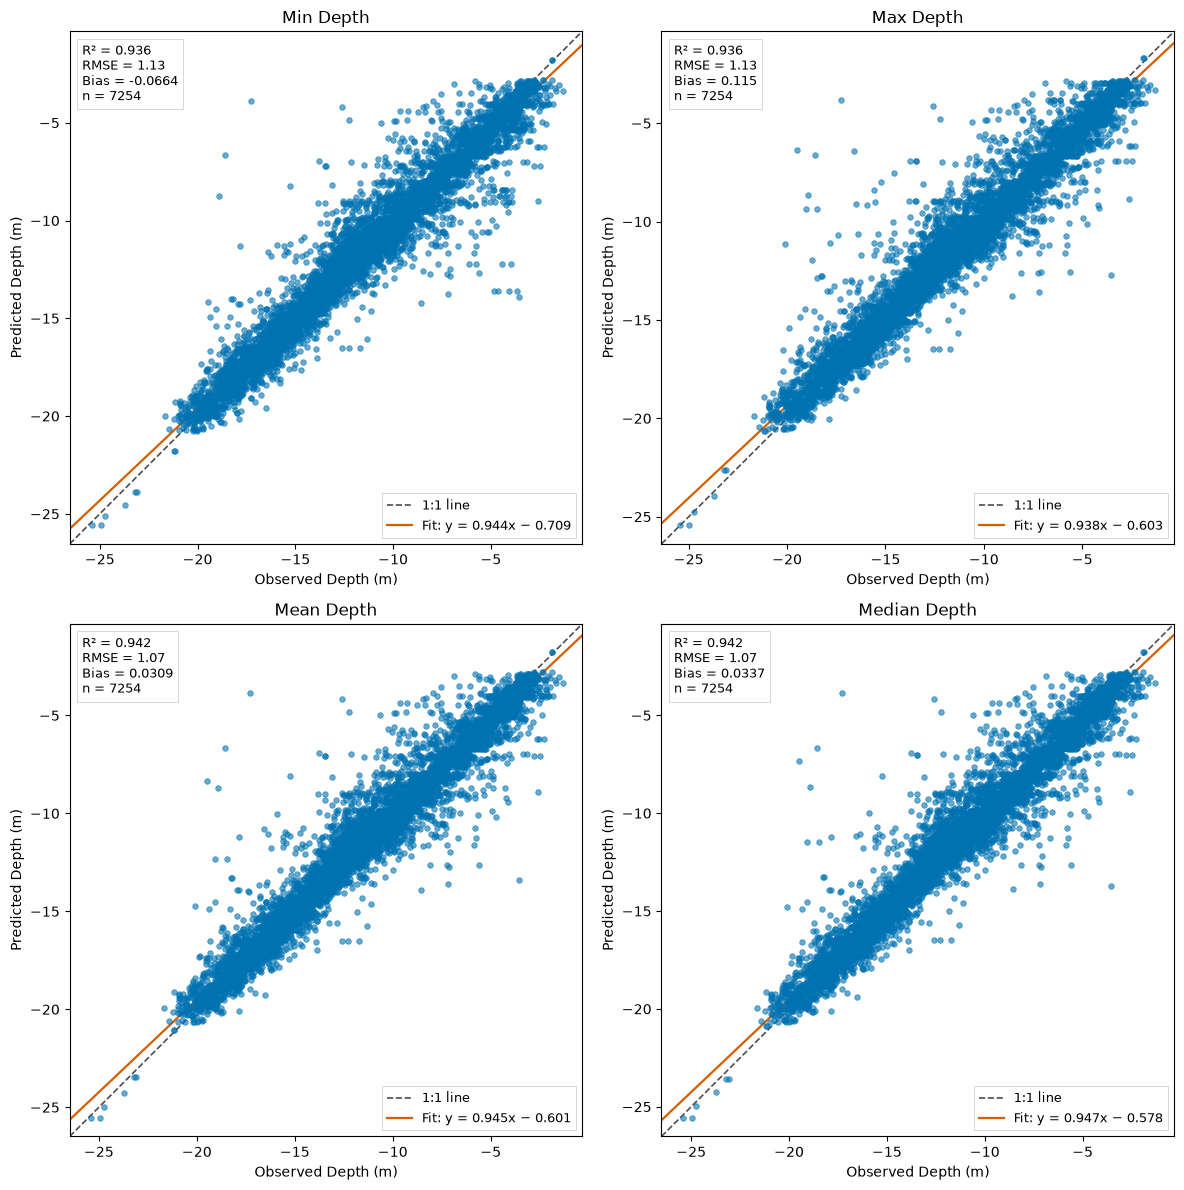

In [16]:
stats_names = ["Min", "Max", "Mean", "Median"]
fig, axs = plt.subplots(2, 2, figsize=(12, 12))
for ax, stat_name, col in zip(axs.ravel(), stats_names, depth_cols):
    _ = rsgispy.regression.regmetrics.plot_pred_vs_obs(
        vld_gpdf,
        ref_col="Depth",
        pred_col=col,
        target_names=["Depth (m)"],
        axs=ax,
    )
    ax.set_title(f"{stat_name} Depth")
fig.tight_layout()

## 12.3 Calculate Quality Statistics

`calc_reg_metrics` is run for each summary and the results combined into a pandas DataFrame. The `nrmse` column is the normalised RMSE (the RMSE as a percentage of the mean reference depth).

In [17]:
reg_stats = dict()
for stat_name, col in zip(stats_names, depth_cols):
    reg_stats[stat_name] = rsgispy.regression.regmetrics.calc_reg_metrics(
        vld_gpdf, ref_col="Depth", pred_col=col
    )

reg_stats_df = pandas.DataFrame.from_dict(reg_stats, orient="index")
reg_stats_df

,r2,rmse,mae,bias,explained_variance,pearson_r,mse,nrmse,nrmse_range,nbias,n_samples
Min,0.936115,1.125623,0.722609,-0.066387,0.936337,0.967679,1.267028,-9.774023,4.665579,0.576455,7254
Max,0.935658,1.129641,0.714238,0.114859,0.936323,0.967639,1.276088,-9.808905,4.682229,-0.997349,7254
Mean,0.942116,1.071455,0.692710,0.030919,0.942164,0.970656,1.148015,-9.303665,4.441055,-0.268472,7254
Median,0.941959,1.072906,0.690827,0.033738,0.942016,0.970588,1.151126,-9.316264,4.447069,-0.292957,7254


In [18]:
# Save to a CSV file so they can be opened as a spreadsheet.
quality_stats_file = os.path.join(out_dir, "bermuda_bathy_quality_stats.csv")
reg_stats_df.to_csv(quality_stats_file)

## 12.4 What do these stats show?

I would start by looking at the r2, RMSE and nRMSE where we can see the mean and median have higher r2 values (0.942) and lower RMSE (1.07 m) and nRMSE (-9.3 %) values than the min and max (r2 0.936, RMSE 1.13 m), which suggests that these are better results, which is probably what we would expect. Comparing the mean and median the values are very close. The min and max are only slightly worse here because the input scenes are clean (the clouds have already been masked); the maps above show that they contain more artifacts away from the ICESat-2 tracks.

Additionally, we can also compare to the Landsat composite result from the previous notebook: the r2 from the composite was 0.938 compared to 0.942, the composite RMSE was 1.11 m compared to 1.07 m and the nRMSE for the composite was -9.6 % compared with -9.3 %. The difference is not significant but it does show a small improvement. You might find this improves further if the input imagery had more noise.

## 12.5 Residuals Analysis for Mean

The residuals are plotted with `plot_residuals` (with a histogram of the residuals) and their normality checked with a QQ plot (`plot_qq_residuals`; the Shapiro-Wilk test is turned off as it is not reliable for more than 5000 values).

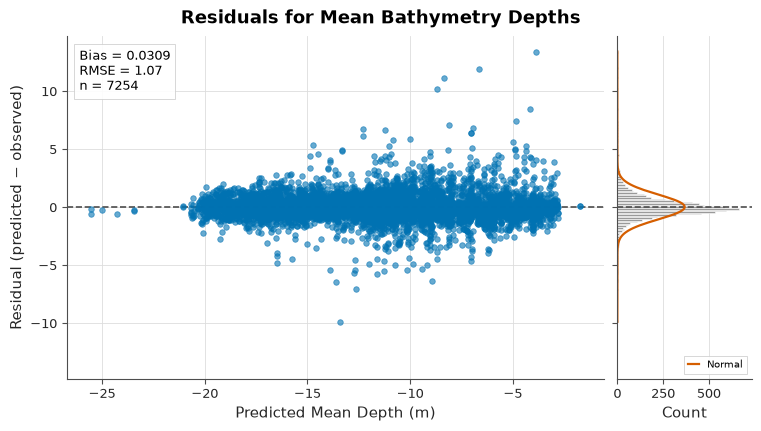

In [19]:
fig, axs = rsgispy.regression.regmetrics.plot_residuals(
    vld_gpdf,
    ref_col="Depth",
    pred_col="mean_depth",
    target_names=["Mean Depth (m)"],
    title="Residuals for Mean Bathymetry Depths",
)

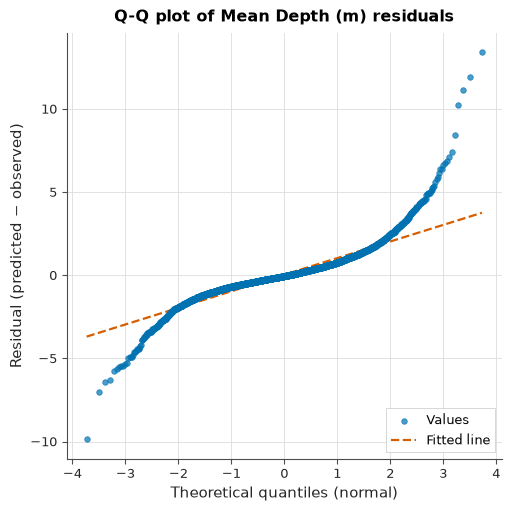

In [20]:
fig, axs = rsgispy.regression.regmetrics.plot_qq_residuals(
    vld_gpdf,
    ref_col="Depth",
    pred_col="mean_depth",
    target_names=["Mean Depth (m)"],
    show_shapiro=False,
)

## 12.6 Residuals Analysis for Median

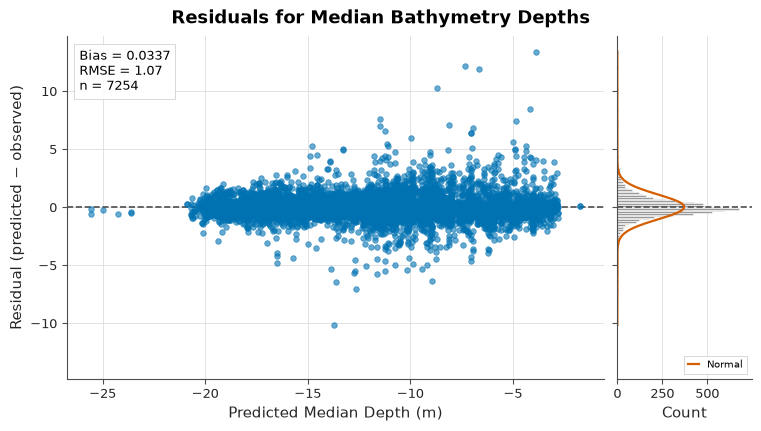

In [21]:
fig, axs = rsgispy.regression.regmetrics.plot_residuals(
    vld_gpdf,
    ref_col="Depth",
    pred_col="median_depth",
    target_names=["Median Depth (m)"],
    title="Residuals for Median Bathymetry Depths",
)

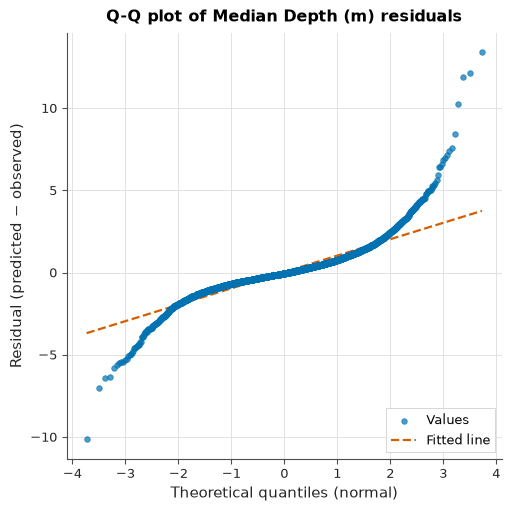

In [22]:
fig, axs = rsgispy.regression.regmetrics.plot_qq_residuals(
    vld_gpdf,
    ref_col="Depth",
    pred_col="median_depth",
    target_names=["Median Depth (m)"],
    show_shapiro=False,
)

# 13. Final Comments

In this case there isn't a significant difference in the residuals of the mean or median summary and the summary statistics are both very similar. Therefore, in choosing the product to make available I would look at them and see if you find any significant differences between the two images and if those differences might justify choosing one over another. However, if like in this case, there is genuinely very little difference between them then I would generally go for the median as it is more robust to noise.

For the example shown in these notebooks there is very little difference between using a satellite image composite or summarising the products from multiple input scenes. However, I would recommend the individual scene based approach, which although it is slightly more complex to implement, produces a per-pixel uncertainty surface and generally better results.